# RoadSafe Chicago | Partie 06 : Analyse exploratoire multivariée

**Projet** : étude de l'accidentologie routière à Chicago (Open Data, API Socrata)
**Données** : 112 056 accidents enregistrés en 2024 (`data/processed/crashes_2024.parquet`)
**Problématique** : *Comment évoluent la fréquence et la gravité des accidents routiers à Chicago, et quels facteurs sont associés à leur gravité ?*

---

### Objectif

La partie 05 a mis en évidence des écarts de gravité selon l'heure, la luminosité, la vitesse affichée ou le type de collision. Mais ces facteurs ne sont pas indépendants : la nuit, la circulation, les types de voie empruntés et les comportements diffèrent de la journée.

Cette partie cherche à savoir si **un écart observé tient toujours lorsqu'on tient compte des autres facteurs**, ou s'il s'explique en réalité par une autre variable : c'est le contrôle des **facteurs de confusion**.

### Méthode

- **Stratification** : on compare les taux de gravité à l'intérieur de sous-groupes homogènes. Par exemple, l'effet de la luminosité est mesuré séparément sur les grands axes et sur les rues résidentielles.
- **Variable de gravité** : `is_severe` (accident mortel ou avec au moins un blessé grave), comme en partie 05.
- **Effectifs minimum** : les croisements multiplient les sous-groupes et réduisent leur taille. Seules les cellules d'au moins 100 accidents sont interprétées.

### Sommaire

1. Nuit × éclairage × gravité : l'éclairage public réduit-il la gravité des accidents nocturnes ?
2. Luminosité × vitesse affichée : l'effet de la nuit persiste-t-il à type de voie égal ?
3. Week-end × tranche horaire : les nuits du week-end sont-elles plus graves que celles de la semaine ?
4. Météo × état de la chaussée : la gravité dépend-elle de la pluie elle-même ou de la chaussée mouillée ?
5. Type de collision × luminosité : les collisions avec piétons sont-elles plus graves la nuit ?

### Précautions de lecture

- Une stratification **réduit** les facteurs de confusion mais ne les élimine pas tous : certains facteurs déterminants, comme l'alcool ou la vitesse réelle, ne figurent pas dans les données.
- Plus un sous-groupe est petit, plus son taux est incertain : l'**intervalle de confiance** reste affiché pour chaque comparaison.
- Les résultats de cette partie orienteront le choix des **hypothèses testées formellement** en partie 07.

## Librairies 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
df = pd.read_parquet("../data/processed/crashes_2024.parquet")
df.head()

,crash_record_id,crash_date,posted_speed_limit,traffic_control_device,device_condition,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,...,delay_valid,injury_info_available,is_injury,is_fatal,is_severe,is_weekend,time_slot,season,is_dark,speed_class
0,5082d6e9f9c5c96660e7ec7fd416549e50d3130af3fc5c...,2024-06-27 13:45:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Journée (10-15h),Été,False,≤20
1,fd34aa4f12f00106b32134531fc6e805590dbe89fef502...,2024-06-22 18:07:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,NOT DIVIDED,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Soir (16-19h),Été,False,25-30
2,f0a652bf48a8c08c8a26cc981e39ed757cd41f8a771761...,2024-06-23 08:41:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,REAR TO REAR,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Matin (6-9h),Été,False,≤20
3,973cda531480f4006c44691e5cc8931b9fd9d719a21264...,2024-06-19 07:35:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,TURNING,T-INTERSECTION,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Matin (6-9h),Été,False,25-30
4,e66fd58b2afc22ec6aa176f149d17467d49f7ae1c83910...,2024-07-07 20:47:00,30,NO CONTROLS,NO CONTROLS,CLEAR,"DARKNESS, LIGHTED ROAD",PARKED MOTOR VEHICLE,OTHER,STRAIGHT AND LEVEL,...,True,True,True,False,False,True,Nuit (20-23h),Été,True,25-30


In [3]:
MOYENNE = df["is_severe"].mean() * 100
LUMIERE = ["DAYLIGHT", "DARKNESS, LIGHTED ROAD", "DARKNESS"]
ORDRE_VITESSE = ["≤20", "25-30", "35-40", "45+"]

In [4]:
# sauvegarde d'une figure dans le dossier reports/figures

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()



In [5]:
# Regroupement de la luminosité en catégories lisibles (UNKNOWN → NA, exclu)
lum_map = {"DAYLIGHT": "Jour", "DARKNESS, LIGHTED ROAD": "Nuit éclairée",
           "DARKNESS": "Nuit non éclairée", "DUSK": "Aube / crépuscule", "DAWN": "Aube / crépuscule"}
df["lum_groupe"] = df["lighting_condition"].astype(str).map(lum_map)
df["periode"] = np.where(df["is_weekend"], "Week-end", "Semaine")

ordre_lum = ["Jour", "Nuit éclairée", "Nuit non éclairée"]

In [6]:
# Calcul de l'intervalle de confiance de Wilson pour un taux de succès
def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    marge = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - marge, centre + marge


In [7]:
# Taux de la cible pour chaque modalité d'une variable, avec effectif et IC à 95 %.


def taux_croise(col_a, col_b, cible="is_severe", min_n=100, exclure=("UNKNOWN",), data=None):
    """Taux de la cible pour chaque combinaison (col_a, col_b), avec effectif et IC à 95 %."""
    d = (df if data is None else data)[[col_a, col_b, cible]].dropna()
    for c in (col_a, col_b):
        d = d[~d[c].astype(str).isin(exclure)]
    g = (d.groupby([col_a, col_b], observed=True)[cible]
          .agg(n="count", k="sum").astype(float).reset_index())
    g = g[g["n"] >= min_n].copy()
    g["taux"] = g["k"] / g["n"] * 100
    bas, haut = wilson(g["k"], g["n"])
    g["ic_bas"], g["ic_haut"] = bas * 100, haut * 100
    return g


In [8]:
# Barres groupées : col_a en abscisse, une couleur par modalité de col_b.


def plot_croise(g, col_a, col_b, ordre_a, ordre_b, titre, nom, xlabel="", legende=""):
    """Barres groupées : col_a en abscisse, une couleur par modalité de col_b."""
    fig, ax = plt.subplots(figsize=(13, 5.5))
    largeur = 0.8 / len(ordre_b)
    palette = sns.color_palette("deep", len(ordre_b))
    for j, b in enumerate(ordre_b):
        sub = g[g[col_b] == b].set_index(col_a).reindex(ordre_a)
        x = np.arange(len(ordre_a)) - 0.4 + largeur * (j + 0.5)
        ax.bar(x, sub["taux"], largeur, color=palette[j], label=str(b),
               yerr=[sub["taux"] - sub["ic_bas"], sub["ic_haut"] - sub["taux"]], capsize=3)
    ax.axhline(MOYENNE, color="crimson", linestyle="--", linewidth=1, label=f"Moyenne : {MOYENNE:.2f} %")
    ax.set_xticks(range(len(ordre_a)))
    ax.set_xticklabels([str(a) for a in ordre_a], rotation=20, ha="right")
    ax.set_title(titre, fontweight="bold"); ax.set_xlabel(xlabel); ax.set_ylabel("% d'accidents graves")
    ax.legend(title=legende, fontsize=9)
    save_fig(nom)

In [9]:
# Taux global, utilisé par plot_croise pour la ligne de moyenne

def heatmap_taux(g, lignes, colonnes, titre, nom, ordre_l, ordre_c):
    """Heatmap des taux, annotée avec les effectifs. Cellules trop petites laissées vides."""
    piv = g.pivot(index=lignes, columns=colonnes, values="taux").reindex(index=ordre_l, columns=ordre_c)
    eff = g.pivot(index=lignes, columns=colonnes, values="n").reindex(index=ordre_l, columns=ordre_c)
    annot = np.where(piv.isna(), "",
                     piv.round(1).astype(str) + " %\nn = " + eff.fillna(0).astype(int).astype(str))
    fig, ax = plt.subplots(figsize=(12, 0.9 * len(ordre_l) + 2))
    sns.heatmap(piv, annot=annot, fmt="", cmap="Reds", ax=ax, linewidths=0.5,
                cbar_kws={"label": "% d'accidents graves"})
    ax.set_title(titre, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
    save_fig(nom)

## 1. Nuit x éclairage x gravité

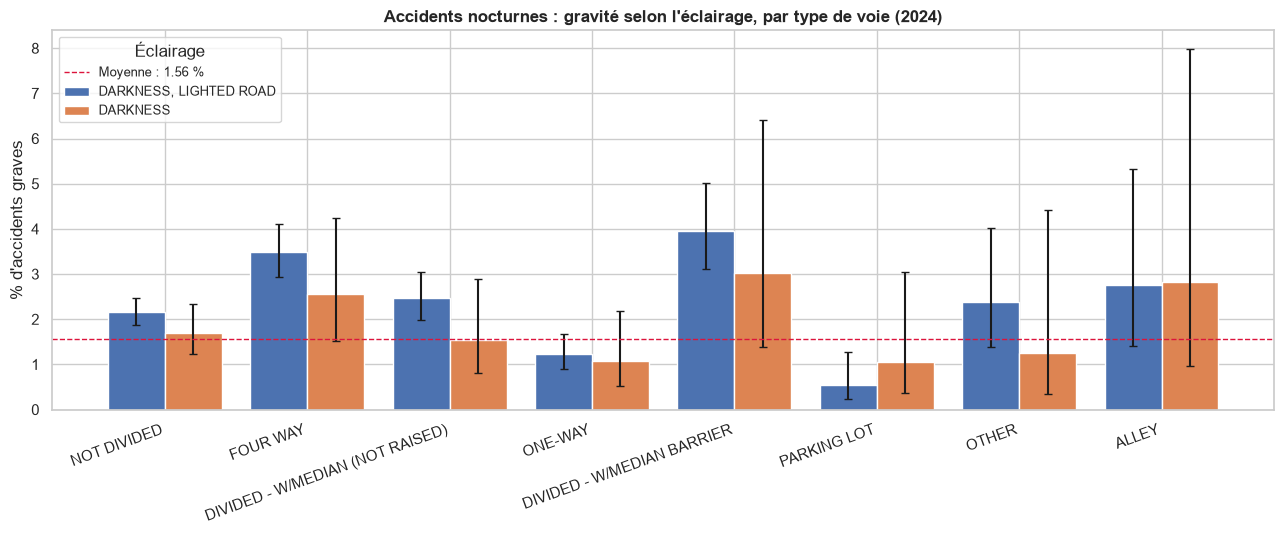

In [10]:
# Gravité des accidents selon l'éclairage, par type de voie


nuit = df[df["lighting_condition"].isin(["DARKNESS, LIGHTED ROAD", "DARKNESS"])]
g = taux_croise("trafficway_type", "lighting_condition", data=nuit)

# On garde les types de voie présents dans les deux conditions d'éclairage
types_ok = g.groupby("trafficway_type", observed=True)["lighting_condition"].nunique()
types_ok = types_ok[types_ok == 2].index
g = g[g["trafficway_type"].isin(types_ok)]
ordre_types = (g.groupby("trafficway_type", observed=True)["n"].sum()
                .sort_values(ascending=False).index.tolist())

plot_croise(g, "trafficway_type", "lighting_condition", ordre_types,
            ["DARKNESS, LIGHTED ROAD", "DARKNESS"],
            "Accidents nocturnes : gravité selon l'éclairage, par type de voie (2024)",
            "06_1_nuit_eclairage_type_voie", legende="Éclairage")

**Analyse.** Sur presque tous les types de voie, la nuit éclairée reste plus grave que la nuit non éclairée (3,48 % contre 2,55 % aux carrefours à quatre branches, 2,47 % contre 1,54 % sur les voies divisées sans terre plein, 2,15 % contre 1,70 % sur les voies non divisées). Seuls les parkings font exception. Le résultat de la partie 05 ne s'explique donc pas uniquement par le type de voie. Deux pistes restent ouvertes : l'éclairage est installé en priorité là où le trafic et les piétons sont nombreux, et les conducteurs roulent probablement plus vite sur une voie bien éclairée. Les effectifs non éclairés restent faibles (100 à 2 200 accidents selon le type), d'où des intervalles de confiance larges.

## 2. Luminosité x vitesse affichée

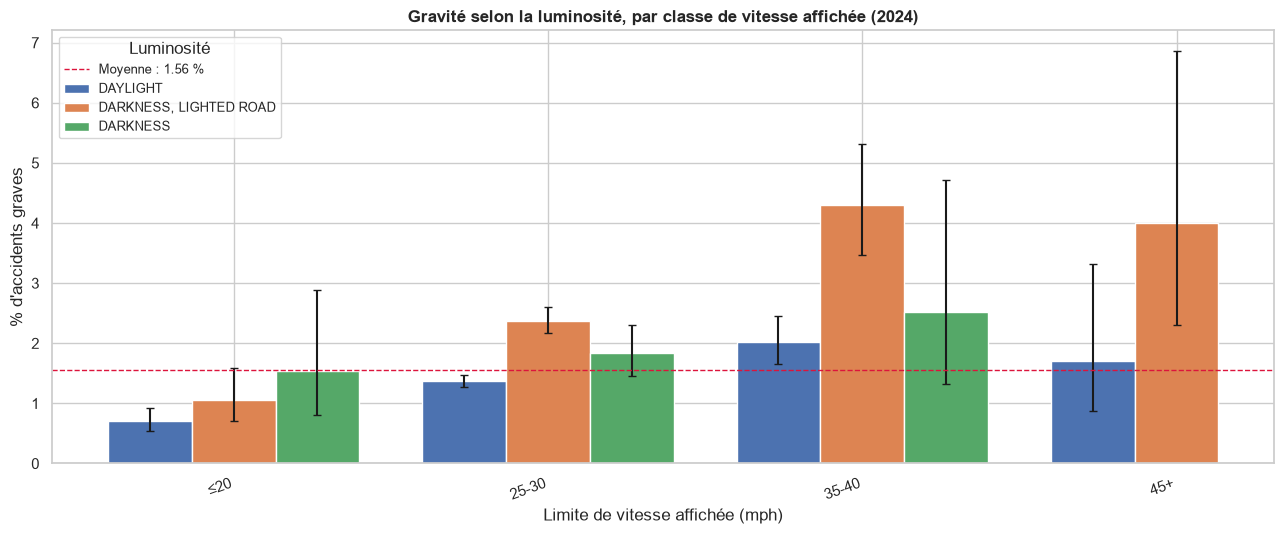

In [11]:
# Gravité des accidents selon la luminosité, par classe de vitesse affichée

g = taux_croise("speed_class", "lighting_condition", data=df[df["speed_valid"]])
g = g[g["lighting_condition"].isin(LUMIERE)]

plot_croise(g, "speed_class", "lighting_condition", ORDRE_VITESSE, LUMIERE,
            "Gravité selon la luminosité, par classe de vitesse affichée (2024)",
            "06_2_luminosite_vitesse", xlabel="Limite de vitesse affichée (mph)", legende="Luminosité")

**Analyse.** À limite de vitesse égale, la nuit reste plus grave que le jour : sur les voies à 25-30 mph, 2,38 % la nuit sur voie éclairée contre 1,37 % de jour ; à 35-40 mph, 4,30 % contre 2,02 %. Les effets de la nuit et de la vitesse se **cumulent** : un accident de nuit sur un axe à 35-40 mph est environ six fois plus souvent grave qu'un accident de jour dans une rue limitée à 20 mph (0,71 %). L'effet de la nuit n'est donc pas un simple effet du type de voie.

## 3. Week-end x tranche horaire

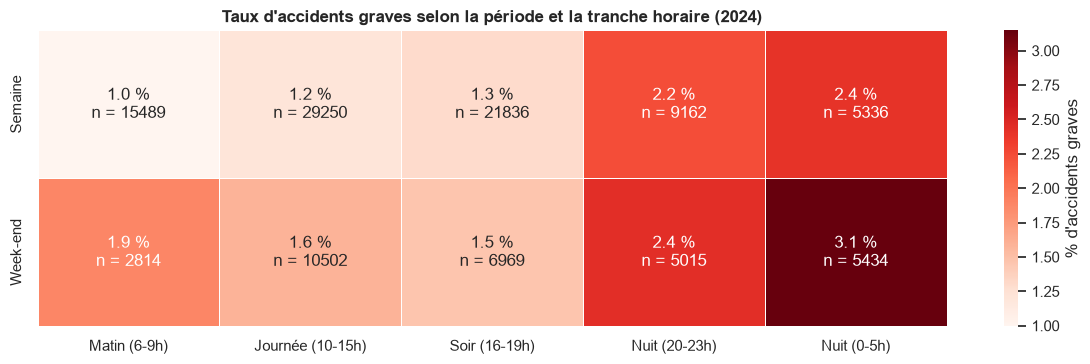

In [12]:
# Gravité des accidents selon la tranche horaire, en semaine et le week-end
g = taux_croise("periode", "time_slot")
ordre_tranches = ["Matin (6-9h)", "Journée (10-15h)", "Soir (16-19h)", "Nuit (20-23h)", "Nuit (0-5h)"]
heatmap_taux(g, "periode", "time_slot",
             "Taux d'accidents graves selon la période et la tranche horaire (2024)",
             "06_3_weekend_tranche_horaire", ["Semaine", "Week-end"], ordre_tranches)

**Analyse.** Dans les deux périodes, la gravité augmente avec la nuit, mais le week-end est plus grave à toutes les heures. L'écart le plus marqué concerne la nuit profonde : 3,1 % d'accidents graves entre 0 h et 5 h le week-end, contre 2,4 % en semaine. Le matin du week-end est aussi presque deux fois plus grave que celui de la semaine (1,9 % contre 1,0 %), probablement parce qu'il prolonge la nuit de sortie, sur des routes peu chargées. Attention : le week-end est défini par le jour calendaire, donc la nuit du vendredi soir (20-23 h) est comptée en semaine et celle du dimanche au lundi (0-5 h) également.

## 4. Météo x état de la chaussée

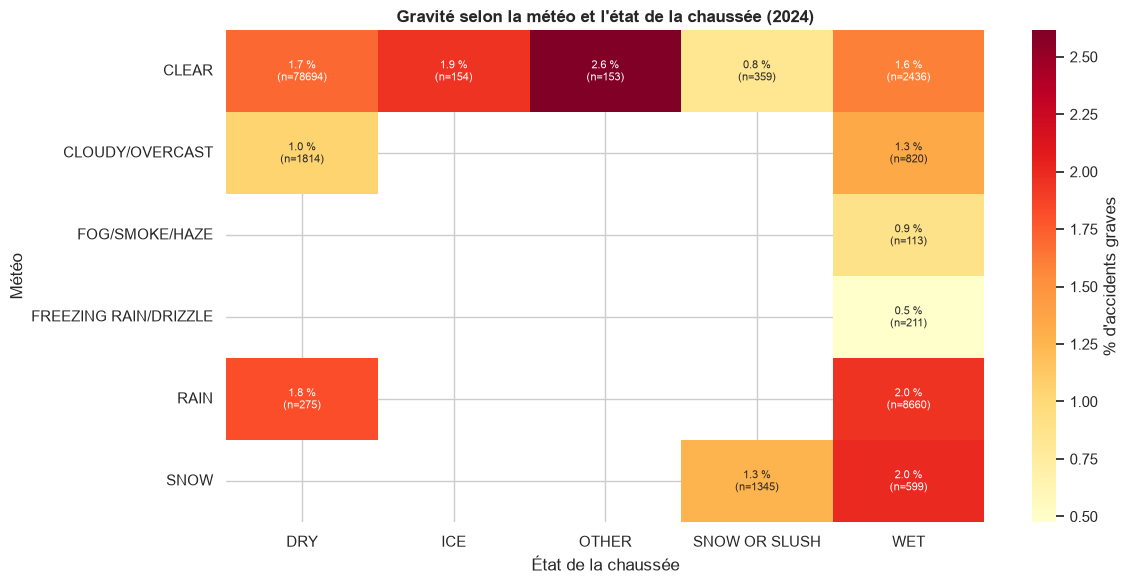

In [13]:
# Gravité des accidents selon la météo et l'état de la chaussée

g = taux_croise("weather_condition", "roadway_surface_cond")
taux = g.pivot(index="weather_condition", columns="roadway_surface_cond", values="taux")
effectifs = g.pivot(index="weather_condition", columns="roadway_surface_cond", values="n")

annotations = taux.round(1).astype(str) + " %\n(n=" + effectifs.fillna(0).astype(int).astype(str) + ")"
annotations = annotations.where(taux.notna(), "")

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(taux, annot=annotations, fmt="", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "% d'accidents graves"}, annot_kws={"fontsize": 8})
ax.set_title("Gravité selon la météo et l'état de la chaussée (2024)", fontweight="bold")
ax.set_xlabel("État de la chaussée"); ax.set_ylabel("Météo")
save_fig("06_4_meteo_chaussee")

**Analyse.** Aucune combinaison ne se détache nettement. Sous la pluie, chaussée sèche (1,82 %) et mouillée (1,95 %) donnent des taux proches ; par temps clair, la chaussée enneigée est même moins grave (0,84 %). Un effet aggravant de la chaussée glissante n'apparaît pas dans ces données, ce qui va dans le sens d'une adaptation de la conduite. Les cellules à faible effectif (glace, autre) sont à lire avec prudence.

## 5. Type de collision x luminosité

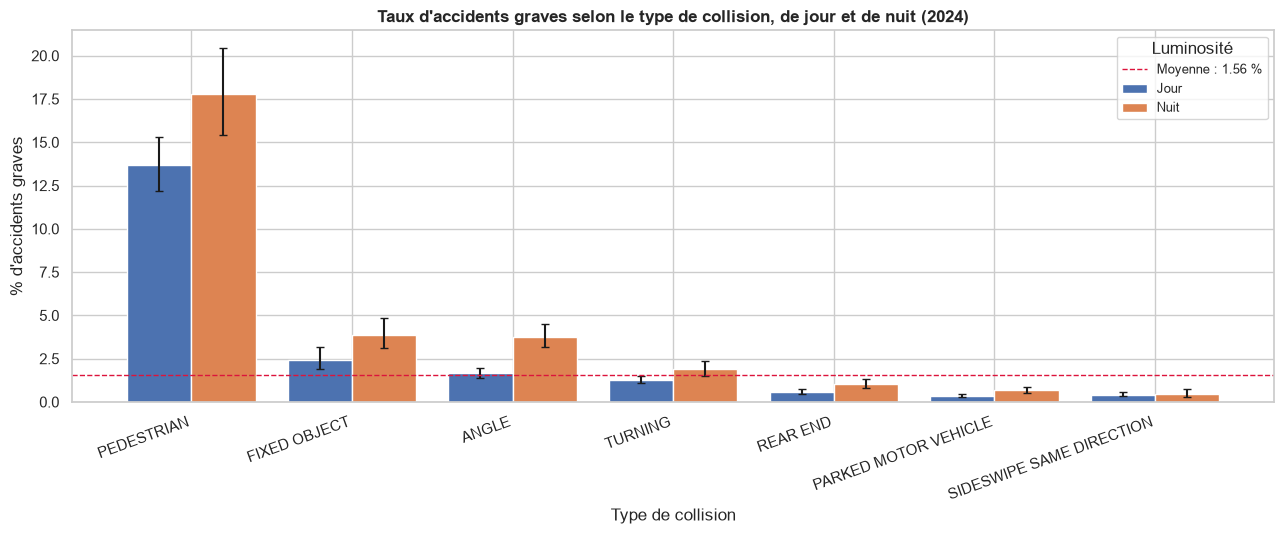

In [14]:
# Gravité des accidents selon le type de collision, de jour et de nuit

top_types = df["first_crash_type"].value_counts().drop("UNKNOWN", errors="ignore").head(7).index.tolist()
d = df[df["first_crash_type"].isin(top_types) & df["lum_groupe"].isin(ordre_lum)].copy()
d["jour_nuit"] = np.where(d["lum_groupe"] == "Jour", "Jour", "Nuit")

g = taux_croise("first_crash_type", "jour_nuit", data=d)
ordre_types = g.groupby("first_crash_type")["taux"].max().sort_values(ascending=False).index.tolist()
plot_croise(g, "first_crash_type", "jour_nuit",
            ordre_a=ordre_types, ordre_b=["Jour", "Nuit"],
            titre="Taux d'accidents graves selon le type de collision, de jour et de nuit (2024)",
            nom="06_5_collision_x_luminosite",
            xlabel="Type de collision", legende="Luminosité")

**Analyse.** Pour six des sept types de collision les plus fréquents, la gravité est nettement plus élevée la nuit ; seul l'accrochage latéral dans le même sens reste stable. Les collisions avec piétons passent de 13,7 % de jour à 17,8 % de nuit, les collisions à angle droit font plus que doubler (1,66 % à 3,77 %), tout comme les accrochages contre un véhicule stationné (0,34 % à 0,66 %). L'effet de la nuit n'est donc pas qu'un effet de composition : il s'observe à type de collision égal.

## Bilan

- **La nuit aggrave la gravité indépendamment du type de voie, de la vitesse affichée et du type de collision.** C'est le résultat le plus solide de cette partie.
- **Vitesse affichée et nuit se cumulent** : les axes rapides la nuit concentrent les accidents les plus graves.
- **L'éclairage public n'apparaît pas protecteur**, mais ce constat reflète probablement un facteur de confusion (trafic, présence de piétons, vitesse pratiquée) que les données ne permettent pas de mesurer.
- **La météo et la chaussée** ne montrent pas d'effet aggravant, même croisées.
- Ces constats sont testés formellement, et ajustés simultanément, dans la partie 07.